In [1]:
!pip install -q scikit-learn matplotlib

In [2]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader, Subset
from torchvision.models import (
    resnet18, ResNet18_Weights,
    vit_b_16, ViT_B_16_Weights
)
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.13.0+cpu
Torchvision version: 0.28.0+cpu
Device: cpu


In [3]:
# ImageNet normalization used by both pretrained models
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load the same CIFAR-10 dataset with model-compatible transforms
train_data_cnn = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True,
    transform=train_transform
)

train_data_vit = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=False,
    transform=train_transform
)

test_data_cnn = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True,
    transform=test_transform
)

test_data_vit = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=False,
    transform=test_transform
)

# Reproducible subset selection
rng = np.random.default_rng(42)
train_indices = rng.choice(50000, 10000, replace=False)
test_indices = rng.choice(10000, 2000, replace=False)

train_subset_cnn = Subset(train_data_cnn, train_indices)
train_subset_vit = Subset(train_data_vit, train_indices)
test_subset_cnn = Subset(test_data_cnn, test_indices)
test_subset_vit = Subset(test_data_vit, test_indices)

batch_size = 16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pin = device.type == "cuda"

train_loader_cnn = DataLoader(
    train_subset_cnn,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=pin
)

train_loader_vit = DataLoader(
    train_subset_vit,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=pin
)

test_loader_cnn = DataLoader(
    test_subset_cnn,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=pin
)

test_loader_vit = DataLoader(
    test_subset_vit,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=pin
)

print("Using device:", device)
print("DataLoaders updated successfully.")
classes = train_data_cnn.classes

print("Classes:", classes)
print("Training images:", len(train_subset_cnn))
print("Testing images:", len(test_subset_cnn))

Using device: cpu
DataLoaders updated successfully.
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 10000
Testing images: 2000


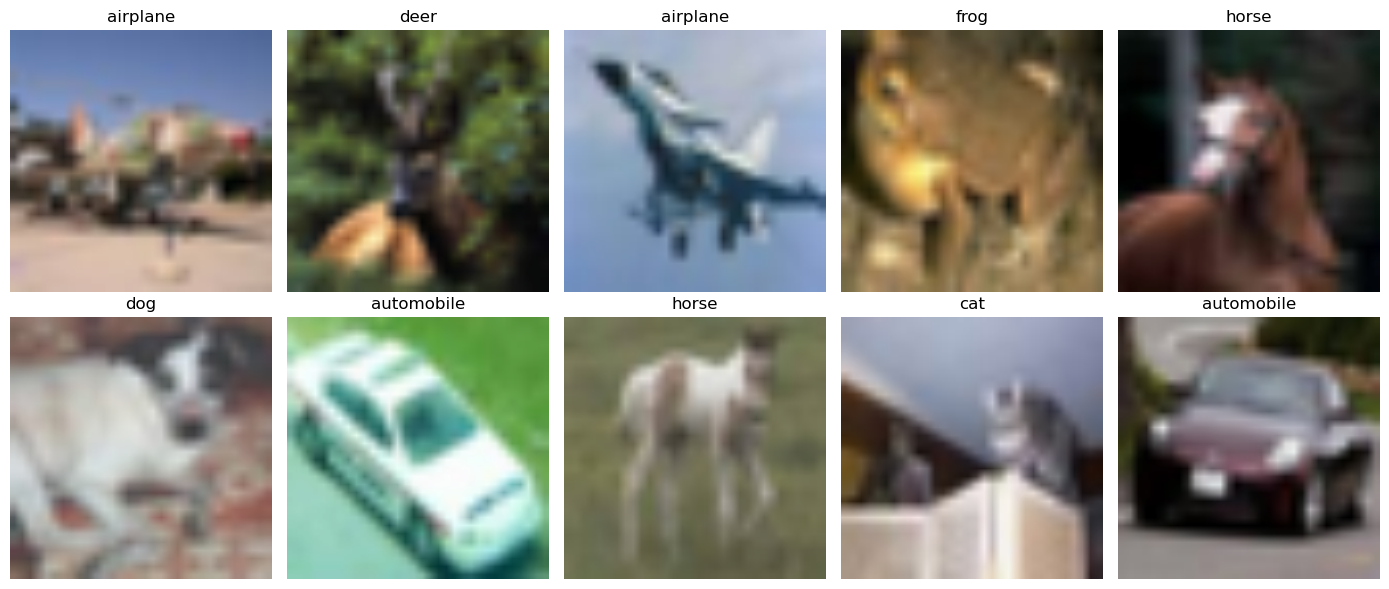

In [4]:
def show_samples(dataset, indices, classes, count=10):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))

    for ax, idx in zip(axes.flat, indices[:count]):
        image, label = dataset[idx]

        # Undo normalization for visualization
        image = image.permute(1, 2, 0).numpy()
        image = image * np.array(std) + np.array(mean)
        image = np.clip(image, 0, 1)

        ax.imshow(image)
        ax.set_title(classes[label])
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(train_data_cnn, train_indices[:10], classes)

In [5]:
cnn_model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace the original 1000-class output layer
cnn_model.fc = nn.Linear(cnn_model.fc.in_features, 10)

cnn_model = cnn_model.to(device)

print(cnn_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [6]:
#loading vit model
vit_model = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)

# Replace the classification head
vit_model.heads.head = nn.Linear(
    vit_model.heads.head.in_features, 10
)

vit_model = vit_model.to(device)

print(vit_model.heads)

Sequential(
  (head): Linear(in_features=768, out_features=10, bias=True)
)


In [7]:
import time
import torch
import torch.nn as nn
import torch.optim as optim

def train_model(model, train_loader, epochs=2, learning_rate=1e-4):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate)

    history = {"loss": [], "accuracy": []}
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_accuracy = 100 * correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Loss: {epoch_loss:.4f} | "
            f"Training Accuracy: {epoch_accuracy:.2f}%"
        )

    training_time = time.time() - start_time
    return model, history, training_time

In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch version: 2.13.0+cpu
CUDA available: False
Device: CPU


In [ ]:
EPOCHS = 2

print("Training CNN (ResNet-18)...")
cnn_model, cnn_history, cnn_time = train_model(
    cnn_model, train_loader_cnn, epochs=EPOCHS
)

print("\nTraining Vision Transformer...")
vit_model, vit_history, vit_time = train_model(
    vit_model, train_loader_vit, epochs=EPOCHS
)

print("\nTraining completed!")
print(f"CNN training time: {cnn_time:.2f} seconds")
print(f"ViT training time: {vit_time:.2f} seconds")

Training CNN (ResNet-18)...


In [ ]:
def evaluate_model(model, test_loader):
    model.eval()
    all_labels = []
    all_predictions = []
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    metrics = {
        "Accuracy (%)": 100 * accuracy_score(
            all_labels, all_predictions
        ),
        "Precision (macro)": precision_score(
            all_labels, all_predictions, average="macro",
            zero_division=0
        ),
        "Recall (macro)": recall_score(
            all_labels, all_predictions, average="macro",
            zero_division=0
        ),
        "F1-score (macro)": f1_score(
            all_labels, all_predictions, average="macro",
            zero_division=0
        ),
        "Test Loss": total_loss / len(test_loader.dataset)
    }

    return metrics, all_labels, all_predictions

In [ ]:
print("Evaluating CNN...")
cnn_metrics, y_true_cnn, y_pred_cnn = evaluate_model(
    cnn_model, test_loader_cnn
)

print("\nEvaluating ViT...")
vit_metrics, y_true_vit, y_pred_vit = evaluate_model(
    vit_model, test_loader_vit
)

for name, metrics in [
    ("CNN (ResNet-18)", cnn_metrics),
    ("Vision Transformer", vit_metrics)
]:
    print(f"\n{name}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

In [ ]:
#comparison table
import pandas as pd

comparison = pd.DataFrame({
    "Metric": list(cnn_metrics.keys()) + ["Training Time (seconds)"],
    "CNN (ResNet-18)": list(cnn_metrics.values()) + [cnn_time],
    "Vision Transformer": list(vit_metrics.values()) + [vit_time]
})

print(comparison.round(4).to_string(index=False))

In [ ]:
#plot the loss curve
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    cnn_history["loss"],
    marker="o",
    label="CNN (ResNet-18)"
)

plt.plot(
    range(1, EPOCHS + 1),
    vit_history["loss"],
    marker="o",
    label="Vision Transformer"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#displaying confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, true, pred, title in [
    (axes[0], y_true_cnn, y_pred_cnn, "CNN (ResNet-18)"),
    (axes[1], y_true_vit, y_pred_vit, "Vision Transformer")
]:
    cm = confusion_matrix(true, pred, labels=range(10))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    display.plot(
        ax=ax, cmap="Blues",
        xticks_rotation=45, colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [ ]:
#classifaction report
print("CNN Classification Report")
print(classification_report(
    y_true_cnn, y_pred_cnn,
    target_names=classes, zero_division=0
))

print("\nVision Transformer Classification Report")
print(classification_report(
    y_true_vit, y_pred_vit,
    target_names=classes, zero_division=0
))

In [ ]:
#testing model on sample dataset
index = 0

image, actual_label = test_data_cnn[test_indices[index]]
batch_image = image.unsqueeze(0).to(device)

cnn_model.eval()
vit_model.eval()

with torch.no_grad():
    cnn_prediction = cnn_model(batch_image).argmax(dim=1).item()
    vit_prediction = vit_model(batch_image).argmax(dim=1).item()

# Display the original, unnormalized image
original = image.permute(1, 2, 0).numpy()
original = np.clip(original * np.array(std) + np.array(mean), 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(original)
plt.axis("off")
plt.title(
    f"Actual: {classes[actual_label]}\n"
    f"CNN: {classes[cnn_prediction]}\n"
    f"ViT: {classes[vit_prediction]}"
)
plt.show()

In [ ]:
#saving trained model
torch.save(cnn_model.state_dict(), "cnn_resnet18.pth")
torch.save(vit_model.state_dict(), "vit_model.pth")

comparison.to_csv("model_comparison.csv", index=False)

print("Models and comparison results saved successfully.")